In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [7]:
prefix = '/mnt/staging/' # or

step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
epochs_lick_root = str(PREPARES / "epochs-licking") + "/"
mouse='cm229'


# licking indices

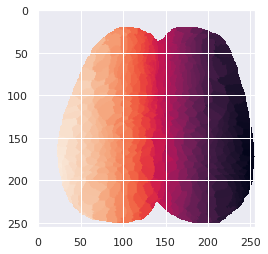

In [4]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [5]:
sensory_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse)

In [6]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

In [8]:
all_gathered = ['M_jrgeco','M_gcamp','M_chbt',
               'M_day_label','M_ind','M_licking',
                'M_is_groom','M_face_pc','M_body_pc',
                'M_LFP_vel','M_RFP_vel','M_rotf']

f = scipy.io.loadmat(epochs_lick_root+mouse+'_raw.mat')

for key in all_gathered:
    exec("{}=f['{}']".format(key,key))
M_ind=np.squeeze(M_ind)

In [10]:
T_PRE = 90
T_POST = 210

In [11]:
bl = range(T_PRE-15,T_PRE)
norm_M_jrgeco = M_jrgeco - np.expand_dims(np.mean(M_jrgeco[:,bl,:],axis=1),axis=1)
norm_M_gcamp = M_gcamp - np.expand_dims(np.mean(M_gcamp[:,bl,:],axis=1),axis=1)
norm_M_chbt = M_chbt - np.expand_dims(np.mean(M_chbt[:,bl,:],axis=1),axis=1)

norm_M_LFP_vel =  M_LFP_vel - np.expand_dims(np.mean(M_LFP_vel[bl,:],axis=0),axis=0)
norm_M_RFP_vel =  M_RFP_vel - np.expand_dims(np.mean(M_RFP_vel[bl,:],axis=0),axis=0)
norm_M_licking =  M_licking - np.expand_dims(np.mean(M_licking[bl,:],axis=0),axis=0)


# lick while running

**first pass**

(29,)


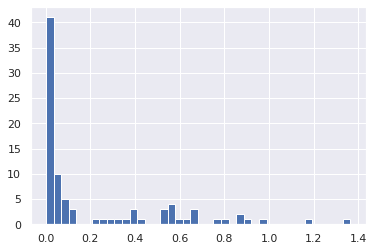

In [12]:
before_running_std = np.std(M_LFP_vel[T_PRE-55:T_PRE-10,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.2
ss_ind = before_running_std>ss
print(np.where(ss_ind==True)[0].shape)




In [13]:
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_licking=M_licking[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]






(60.0, 120.0)

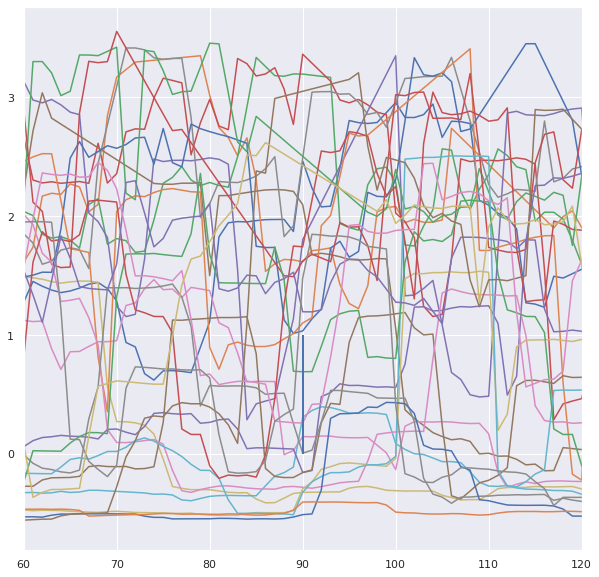

In [14]:
plt.figure(figsize=(10,10))
for i in range(M_LFP_vel.shape[1]):
    plt.plot(M_LFP_vel[:,i]+0.0*i)
plt.vlines(range(T_PRE,T_PRE+1),0, 1,linewidth = 2)
plt.xlim([T_PRE-30,T_PRE+30])

**second pass**

(20,)


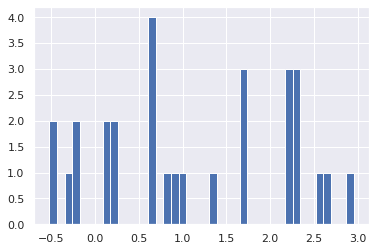

In [15]:
before_running_std = np.mean(M_LFP_vel[T_PRE-40:T_PRE,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.5
ss_ind = before_running_std>ss
print(np.where(ss_ind==True)[0].shape)

In [16]:
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_licking=M_licking[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]






(60.0, 120.0)

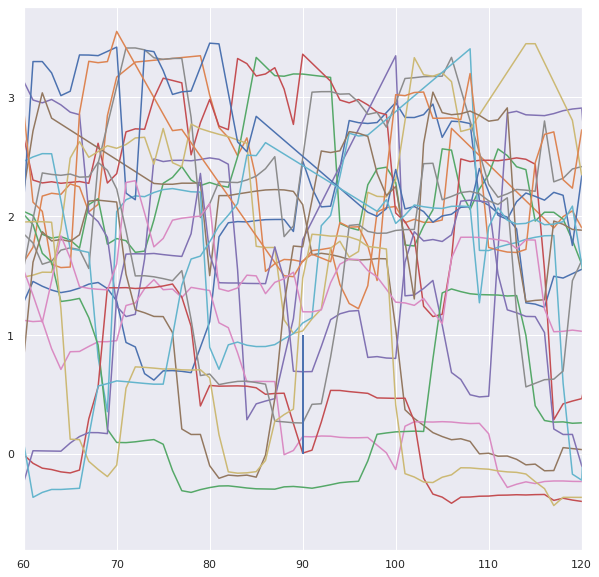

In [17]:
plt.figure(figsize=(10,10))
for i in range(M_LFP_vel.shape[1]):
    plt.plot(M_LFP_vel[:,i]+0.0*i)
plt.vlines(range(T_PRE,T_PRE+1),0, 1,linewidth = 2)
plt.xlim([T_PRE-30,T_PRE+30])

**third pass**

(20,)


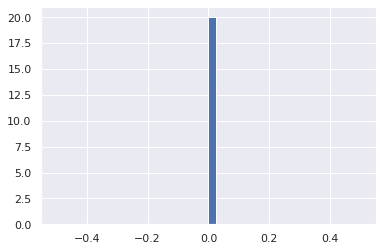

In [18]:
before_running_std = np.mean(M_licking[T_PRE-15:T_PRE,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.1
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)

In [19]:
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_licking=M_licking[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]






(19,)


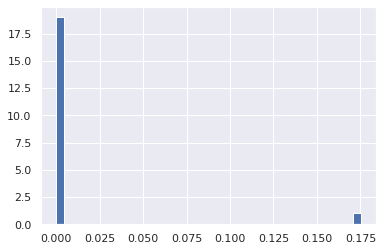

In [20]:
before_running_std = np.std(M_is_groom[T_PRE-15:T_PRE+15,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.1
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)

In [21]:
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_licking=M_licking[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]






**baseline**

In [22]:
bl = range(T_PRE-15,T_PRE-5)
norm_M_jrgeco = M_jrgeco - np.expand_dims(np.mean(M_jrgeco[:,bl,:],axis=1),axis=1)
norm_M_gcamp = M_gcamp - np.expand_dims(np.mean(M_gcamp[:,bl,:],axis=1),axis=1)
norm_M_chbt = M_chbt - np.expand_dims(np.mean(M_chbt[:,bl,:],axis=1),axis=1)

norm_M_LFP_vel =  M_LFP_vel - np.expand_dims(np.mean(M_LFP_vel[bl,:],axis=0),axis=0)
norm_M_RFP_vel =  M_RFP_vel - np.expand_dims(np.mean(M_RFP_vel[bl,:],axis=0),axis=0)
norm_M_licking =  M_licking - np.expand_dims(np.mean(M_licking[bl,:],axis=0),axis=0)


(60.0, 120.0)

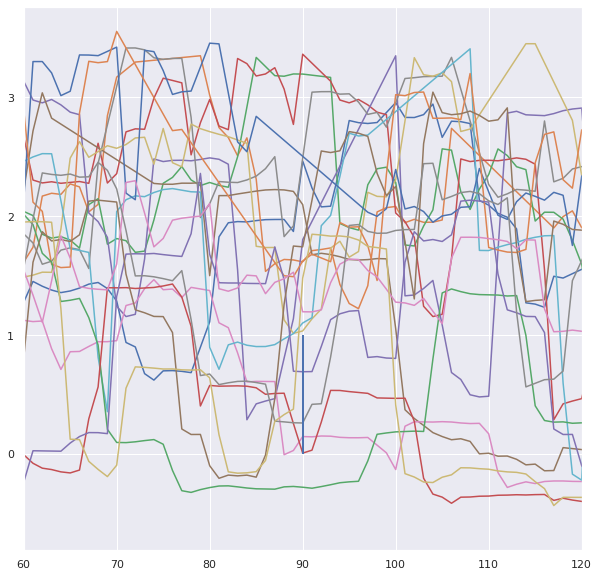

In [23]:
plt.figure(figsize=(10,10))
for i in range(M_LFP_vel.shape[1]):
    plt.plot(M_LFP_vel[:,i]+0.0*i)
plt.vlines(range(T_PRE,T_PRE+1),0, 1,linewidth = 2)
plt.xlim([T_PRE-30,T_PRE+30])

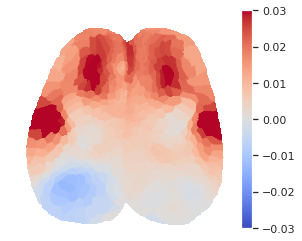

In [24]:
# show_map(np.mean(np.mean(np.abs(norm_M_jrgeco[:,T_PRE:T_PRE+15,:]),axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)
# show_map(np.mean(norm_M_jrgeco[:,T_PRE:T_PRE+5,5],axis=1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)
show_map(np.mean(np.mean(norm_M_jrgeco[:,T_PRE:T_PRE+5,:],axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)


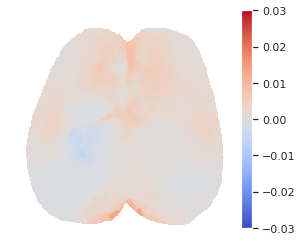

In [25]:
show_map(np.mean(np.mean(norm_M_gcamp[:,T_PRE:T_PRE+5,:],axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)


(60.0, 120.0)

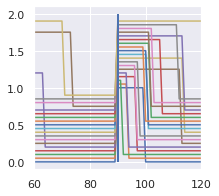

In [26]:
plt.figure(figsize=(3,3))
for i in range(norm_M_licking.shape[1]):
    plt.plot(M_licking[:,i]+0.05*i)
plt.vlines(range(T_PRE,T_PRE+1),0, 2,linewidth = 2)
plt.xlim([T_PRE-30,T_PRE+30])

<AxesSubplot:>

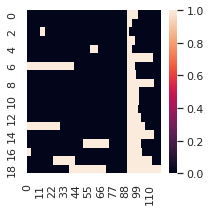

In [27]:
plt.figure(figsize=(3,3))
sns.heatmap(norm_M_licking[:120,:].T,vmax=1)

In [28]:
bl = range(T_PRE-15,T_PRE-5)
norm_M_jrgeco = M_jrgeco - np.expand_dims(np.mean(M_jrgeco[:,bl,:],axis=1),axis=1)
norm_M_gcamp = M_gcamp - np.expand_dims(np.mean(M_gcamp[:,bl,:],axis=1),axis=1)
norm_M_chbt = M_chbt - np.expand_dims(np.mean(M_chbt[:,bl,:],axis=1),axis=1)

norm_M_LFP_vel =  M_LFP_vel - np.expand_dims(np.mean(M_LFP_vel[bl,:],axis=0),axis=0)
norm_M_RFP_vel =  M_RFP_vel - np.expand_dims(np.mean(M_RFP_vel[bl,:],axis=0),axis=0)
norm_M_licking =  M_licking - np.expand_dims(np.mean(M_licking[bl,:],axis=0),axis=0)


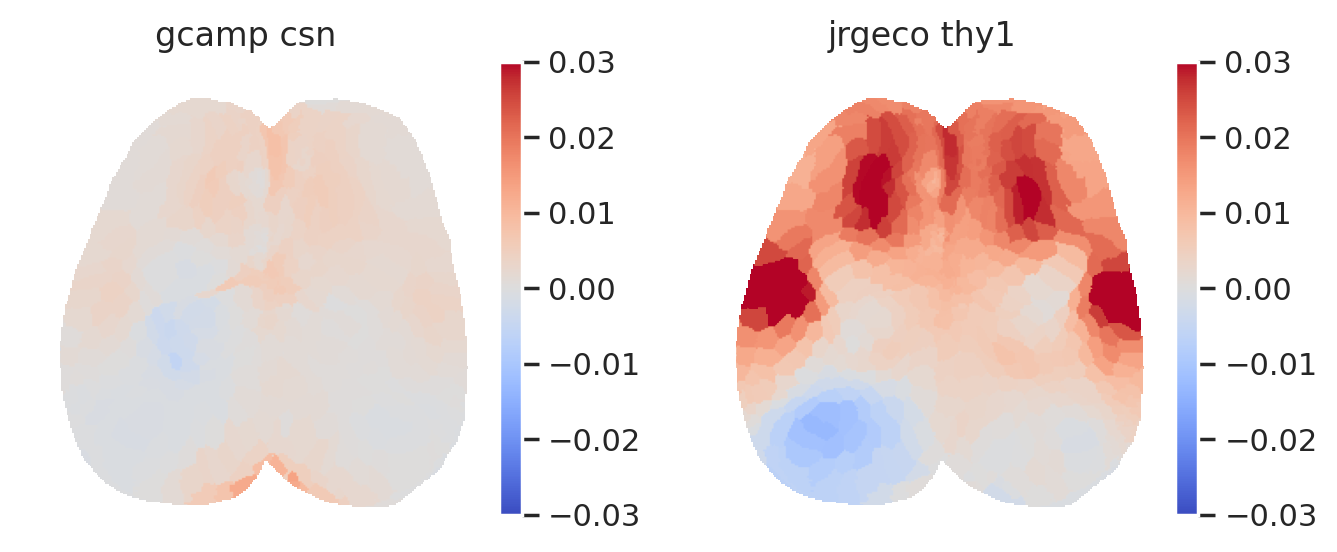

In [29]:
# show_map(np.mean(np.mean(np.abs(norm_M_jrgeco[:,T_PRE:T_PRE+15,:]),axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)
plt.figure(figsize=(8,3),dpi=200)
plt.subplot(121)

show_map(np.mean(np.mean(norm_M_gcamp[:,T_PRE:T_PRE+5,:],axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)
plt.title('gcamp csn')
plt.subplot(122)
plt.title('jrgeco thy1')
show_map(np.mean(np.mean(norm_M_jrgeco[:,T_PRE:T_PRE+5,:],axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)

# show_map(np.mean(np.mean(norm_M_jrgeco[:,T_PRE:T_PRE+5,:],axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)


In [30]:
all_gathered = ['M_jrgeco','M_gcamp','M_chbt',
               'M_day_label','M_ind','M_licking',
                'M_is_groom','M_face_pc','M_body_pc',
                'M_LFP_vel','M_RFP_vel','M_rotf']

all_gathered_dict = {key:[] for key in all_gathered}
for key in all_gathered_dict:
    exec("all_gathered_dict[key] = {}".format(key))


scipy.io.savemat(epochs_lick_root+mouse+'_lick-during-run.mat',
                       all_gathered_dict)
